<a href="https://colab.research.google.com/github/Sarah-Jack05/encs4380-dynamics--Mazion-/blob/main/Module2_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


FIRST-ORDER FREQUENCY RESPONSE
Time constant:       0.2000 s
Input amplitude:     1.0000
Angular frequency:   2.0000 rad/s
Amplitude ratio:     0.9285
Output amplitude:    0.9285
Phase lag:           -21.8014 degrees
Time lag:            0.1903 s
Cutoff frequency:    5.0000 rad/s
Dynamic error:       -7.15%


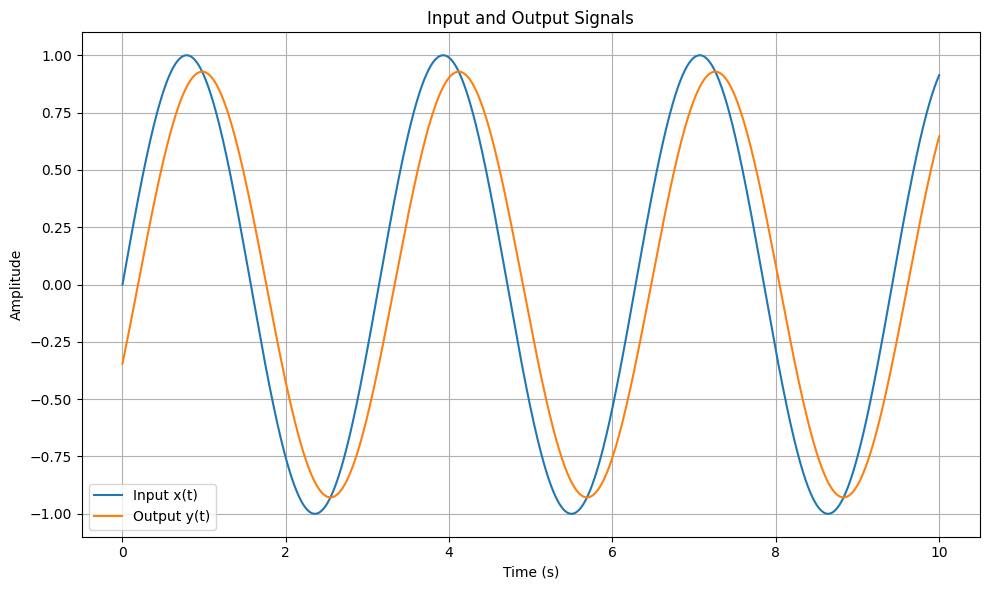

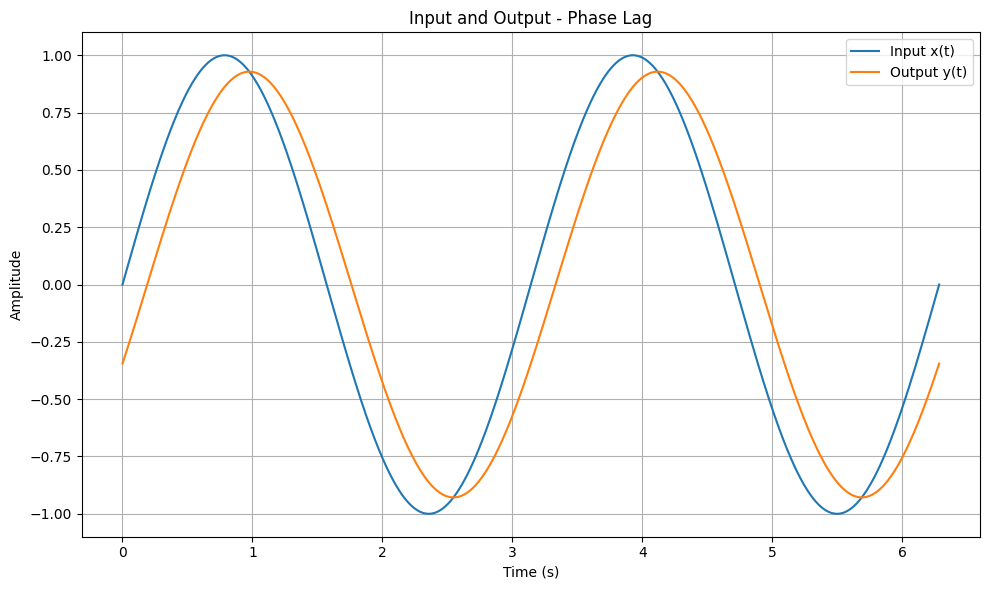

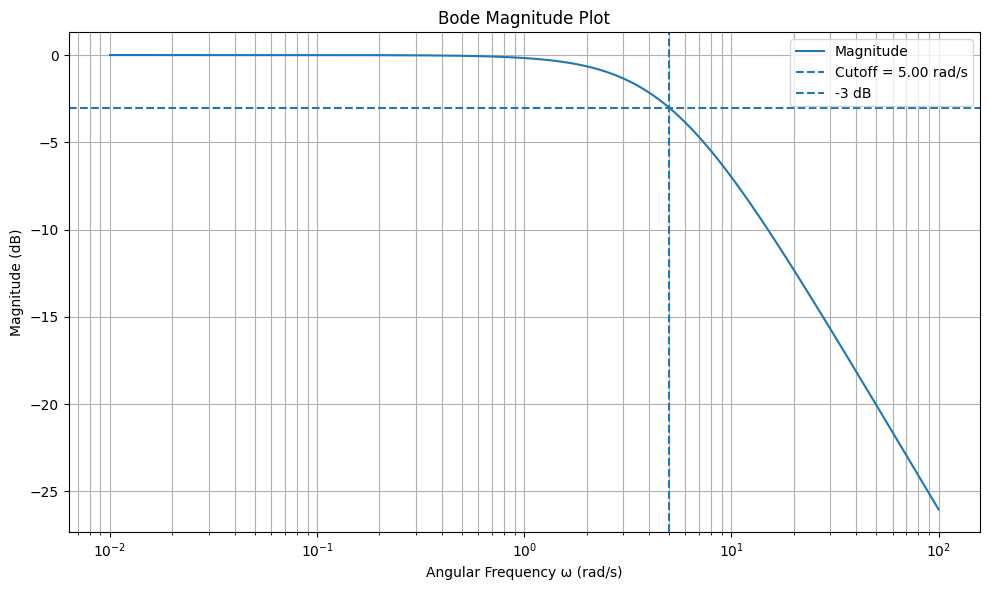

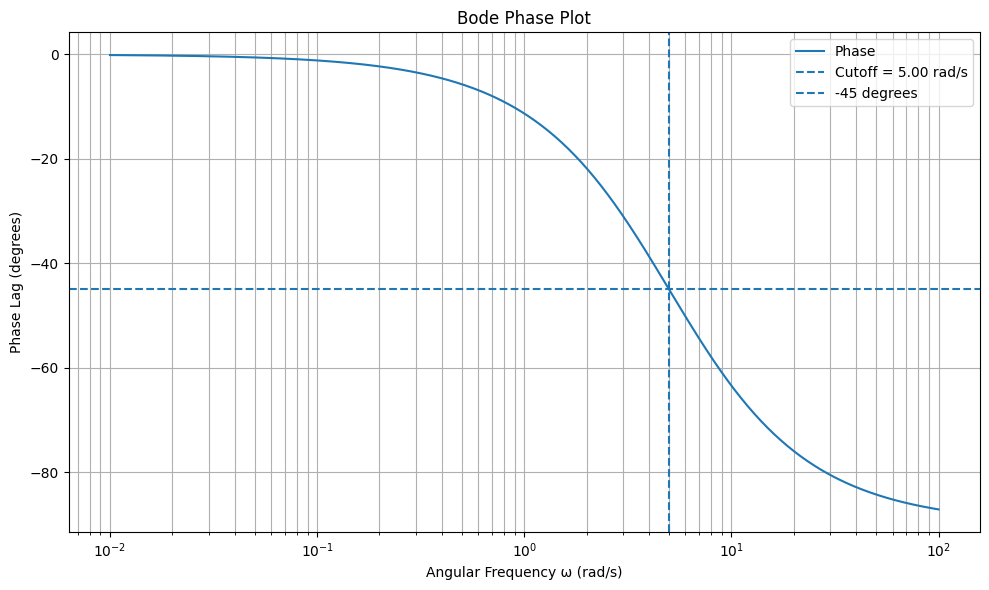

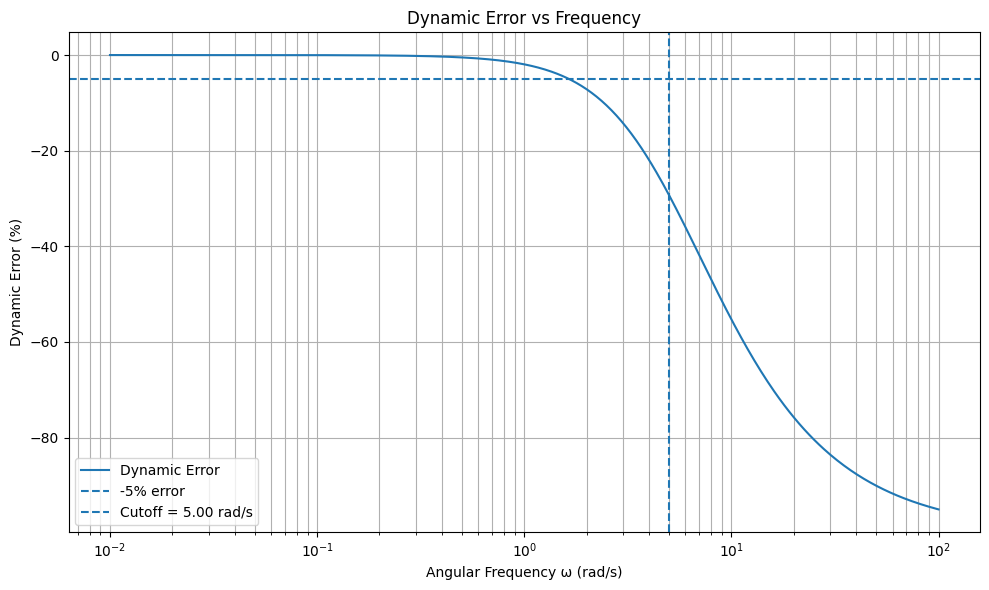


VALIDATION CHECK 1
Amplitude ratio = 0.9285
Phase lag       = -21.8014 degrees
✓ Amplitude ratio PASSED
✓ Phase lag PASSED

VALIDATION CHECK 3
Maximum frequency:    100 Hz
Maximum error:        5.0%
Maximum tau:          0.523 ms
Phase lag at 50 Hz:   9.33 degrees
✓ Maximum tau PASSED
✓ Phase lag PASSED

REUSABLE SIMULATION FUNCTION TEST
frequency_hz             : 0.3183
omega                    : 2.0000
tau                      : 0.2000
input_amplitude          : 1.0000
amplitude_ratio          : 0.9285
output_amplitude         : 0.9285
phase_lag_deg            : -21.8014
time_lag                 : 0.1903
cutoff_frequency         : 5.0000
dynamic_error            : -0.0715
dynamic_error_percent    : -7.1523


In [15]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Calculation Functions
# ============================================================

def calculate_amplitude_ratio(omega, tau):
    if tau <= 0:
        raise ValueError("Tau must be positive.")
    return 1 / np.sqrt(1 + (omega * tau)**2)


def calculate_phase_lag(omega, tau):
    if tau <= 0:
        raise ValueError("Tau must be positive.")
    return np.degrees(-np.arctan(omega * tau))


def calculate_output_amplitude(A, omega, tau):
    return A * calculate_amplitude_ratio(omega, tau)


def calculate_cutoff_frequency(tau):
    if tau <= 0:
        raise ValueError("Tau must be positive.")
    return 1 / tau


def calculate_dynamic_error(omega, tau):
    return calculate_amplitude_ratio(omega, tau) - 1


def calculate_max_tau_for_error(frequency_hz, max_error=0.05):
    if frequency_hz <= 0 or not 0 < max_error < 1:
        raise ValueError("Invalid frequency or error.")

    omega = 2 * np.pi * frequency_hz
    M_min = 1 - max_error
    return np.sqrt(1 / M_min**2 - 1) / omega


def calculate_phase_lag_at_frequency(tau, frequency_hz):
    if tau <= 0 or frequency_hz <= 0:
        raise ValueError("Tau and frequency must be positive.")

    return calculate_phase_lag(2 * np.pi * frequency_hz, tau)


def simulate_frequency_response(tau, frequency_hz, A=1.0):
    if tau <= 0 or frequency_hz <= 0 or A <= 0:
        raise ValueError("Inputs must be positive.")

    omega = 2 * np.pi * frequency_hz
    M = calculate_amplitude_ratio(omega, tau)
    phase = calculate_phase_lag(omega, tau)
    phase_rad = np.radians(phase)
    error = M - 1

    return {
        "frequency_hz": frequency_hz,
        "omega": omega,
        "tau": tau,
        "input_amplitude": A,
        "amplitude_ratio": M,
        "output_amplitude": A * M,
        "phase_lag_deg": phase,
        "time_lag": abs(phase_rad) / omega,
        "cutoff_frequency": 1 / tau,
        "dynamic_error": error,
        "dynamic_error_percent": error * 100
    }


# ============================================================
# 2. Simulation Parameters
# ============================================================

tau = 0.2
omega = 2.0
A = 1.0

t = np.linspace(0, 10, 2000)

# ============================================================
# 3. Calculate Response and Generate Signals
# ============================================================

M = calculate_amplitude_ratio(omega, tau)
phi_deg = calculate_phase_lag(omega, tau)
phi_rad = np.radians(phi_deg)

A_out = calculate_output_amplitude(A, omega, tau)
omega_c = calculate_cutoff_frequency(tau)
dynamic_error = calculate_dynamic_error(omega, tau)
time_lag = abs(phi_rad) / omega

x = A * np.sin(omega * t)
y = A_out * np.sin(omega * t + phi_rad)

# ============================================================
# 4. Print Simulation Results
# ============================================================

print("\n" + "=" * 55)
print("FIRST-ORDER FREQUENCY RESPONSE")
print("=" * 55)

print(f"Time constant:       {tau:.4f} s")
print(f"Input amplitude:     {A:.4f}")
print(f"Angular frequency:   {omega:.4f} rad/s")
print(f"Amplitude ratio:     {M:.4f}")
print(f"Output amplitude:    {A_out:.4f}")
print(f"Phase lag:           {phi_deg:.4f} degrees")
print(f"Time lag:            {time_lag:.4f} s")
print(f"Cutoff frequency:    {omega_c:.4f} rad/s")
print(f"Dynamic error:       {dynamic_error * 100:.2f}%")
print("=" * 55)


# ============================================================
# 5. Input and Output Signals
# ============================================================

def finish_plot(title, ylabel):
    plt.xlabel("Time (s)")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


plt.figure(figsize=(10, 6))
plt.plot(t, x, label="Input x(t)")
plt.plot(t, y, label="Output y(t)")
finish_plot("Input and Output Signals", "Amplitude")


# Show phase lag clearly
period = 2 * np.pi / omega
mask = t <= 2 * period

plt.figure(figsize=(10, 6))
plt.plot(t[mask], x[mask], label="Input x(t)")
plt.plot(t[mask], y[mask], label="Output y(t)")
finish_plot("Input and Output - Phase Lag", "Amplitude")


# ============================================================
# 6. Frequency Sweep
# ============================================================

omega_values = np.logspace(-2, 2, 500)

M_values = calculate_amplitude_ratio(omega_values, tau)
phase_values = calculate_phase_lag(omega_values, tau)
error_values = (M_values - 1) * 100


# ============================================================
# 7. Bode Magnitude Plot
# ============================================================

plt.figure(figsize=(10, 6))
plt.semilogx(omega_values, 20 * np.log10(M_values),
             label="Magnitude")
plt.axvline(omega_c, linestyle="--",
            label=f"Cutoff = {omega_c:.2f} rad/s")
plt.axhline(-3.01, linestyle="--", label="-3 dB")

plt.xlabel("Angular Frequency ω (rad/s)")
plt.ylabel("Magnitude (dB)")
plt.title("Bode Magnitude Plot")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 8. Bode Phase Plot
# ============================================================

plt.figure(figsize=(10, 6))
plt.semilogx(omega_values, phase_values, label="Phase")
plt.axvline(omega_c, linestyle="--",
            label=f"Cutoff = {omega_c:.2f} rad/s")
plt.axhline(-45, linestyle="--", label="-45 degrees")

plt.xlabel("Angular Frequency ω (rad/s)")
plt.ylabel("Phase Lag (degrees)")
plt.title("Bode Phase Plot")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 9. Dynamic Error Plot
# ============================================================

plt.figure(figsize=(10, 6))
plt.semilogx(omega_values, error_values, label="Dynamic Error")
plt.axhline(-5, linestyle="--", label="-5% error")
plt.axvline(omega_c, linestyle="--",
            label=f"Cutoff = {omega_c:.2f} rad/s")

plt.xlabel("Angular Frequency ω (rad/s)")
plt.ylabel("Dynamic Error (%)")
plt.title("Dynamic Error vs Frequency")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 10. Validation Check 1
# ============================================================

print("\n" + "=" * 55)
print("VALIDATION CHECK 1")
print("=" * 55)

print(f"Amplitude ratio = {M:.4f}")
print(f"Phase lag       = {phi_deg:.4f} degrees")

print("✓ Amplitude ratio PASSED" if abs(M - 0.93) < 0.01
      else "✗ Amplitude ratio FAILED")

print("✓ Phase lag PASSED" if abs(phi_deg + 21.8) < 0.5
      else "✗ Phase lag FAILED")


# ============================================================
# 11. Validation Check 3
# ============================================================

frequency_max = 100
frequency_phase = 50
max_error = 0.05

tau_max = calculate_max_tau_for_error(frequency_max, max_error)
phase_at_50hz = calculate_phase_lag_at_frequency(
    tau_max, frequency_phase
)

print("\n" + "=" * 55)
print("VALIDATION CHECK 3")
print("=" * 55)

print(f"Maximum frequency:    {frequency_max} Hz")
print(f"Maximum error:        {max_error * 100:.1f}%")
print(f"Maximum tau:          {tau_max * 1000:.3f} ms")
print(f"Phase lag at 50 Hz:   {abs(phase_at_50hz):.2f} degrees")

print("✓ Maximum tau PASSED" if abs(tau_max * 1000 - 0.52) < 0.02
      else "✗ Maximum tau FAILED")

print("✓ Phase lag PASSED" if abs(abs(phase_at_50hz) - 9.3) < 0.2
      else "✗ Phase lag FAILED")


# ============================================================
# 12. Reusable Simulation Function Test
# ============================================================

results = simulate_frequency_response(
    tau=0.2,
    frequency_hz=2 / (2 * np.pi),
    A=1.0
)

print("\n" + "=" * 55)
print("REUSABLE SIMULATION FUNCTION TEST")
print("=" * 55)

for key, value in results.items():
    print(f"{key:25}: {value:.4f}")

print("=" * 55)
